# **LABSHEET - 1(Part-B)**

**1. Build a tool that loads any image format(JPG/PNG/BMP) and displays its key properties, dimensions, number of channels, data type and file size.**

          IMAGE PROPERTIES
File Name        : pic(dog).jpg
Image Format     : JPEG
Width            : 1920 pixels
Height           : 1080 pixels
Dimensions       : 1080 x 1920
Number of Channels: 3
Data Type        : uint8
File Size        : 277.82 KB
File Size        : 0.27 MB


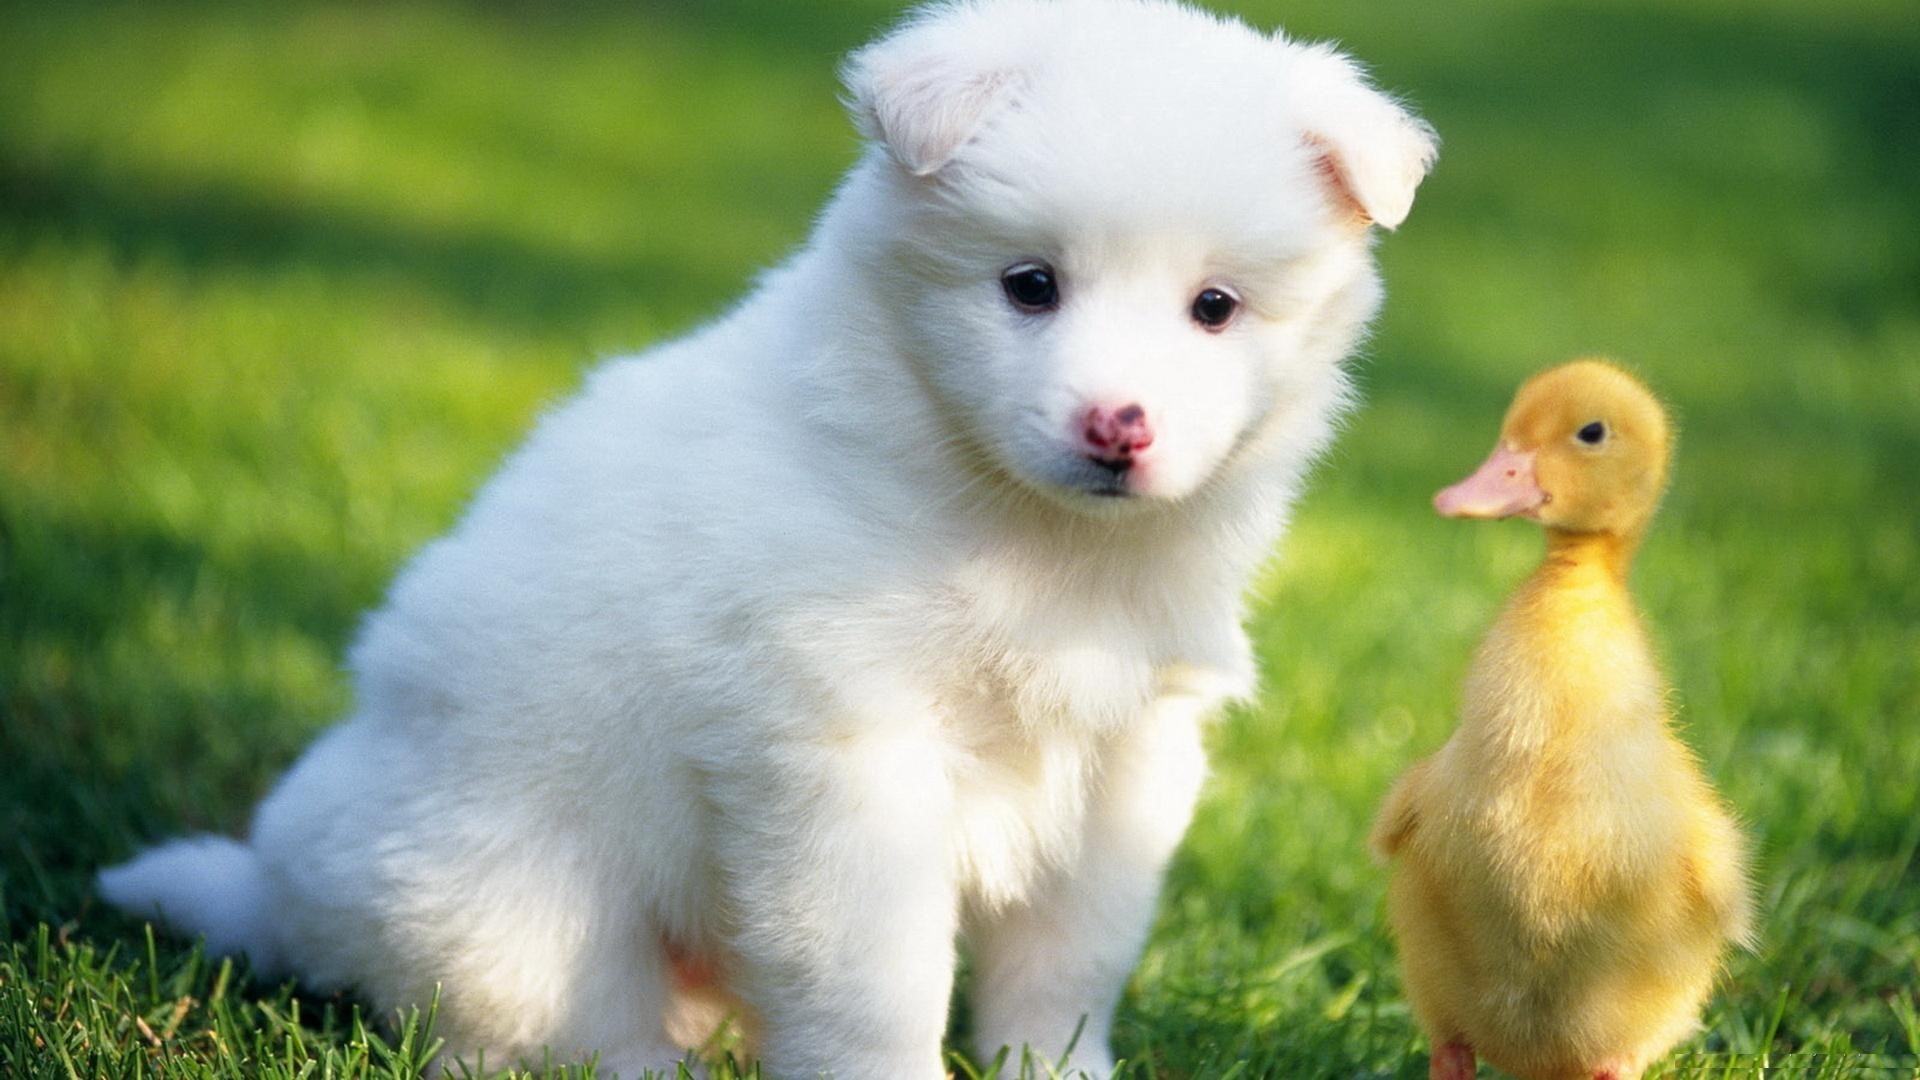

In [1]:
from PIL import Image
import numpy as np
import os

# Image filename
filename = "pic(dog).jpg"

# Open the image
img = Image.open(filename)

# Convert image to NumPy array
img_array = np.array(img)

# Get image dimensions
width, height = img.size

# Get number of channels
if len(img_array.shape) == 2:
    channels = 1
else:
    channels = img_array.shape[2]

# Get data type
data_type = img_array.dtype

# Get file size
file_size_bytes = os.path.getsize(filename)
file_size_kb = file_size_bytes / 1024
file_size_mb = file_size_kb / 1024

# Display image properties
print("========================================")
print("          IMAGE PROPERTIES")
print("========================================")

print("File Name        :", filename)
print("Image Format     :", img.format)
print("Width            :", width, "pixels")
print("Height           :", height, "pixels")
print("Dimensions       :", height, "x", width)
print("Number of Channels:", channels)
print("Data Type        :", data_type)
print("File Size        :", round(file_size_kb, 2), "KB")
print("File Size        :", round(file_size_mb, 2), "MB")

print("========================================")

# Display the image
display(img)

**2. Create a program that reads a color image, convert it to grayscale, and saves both versions side by side for visual comparison.**

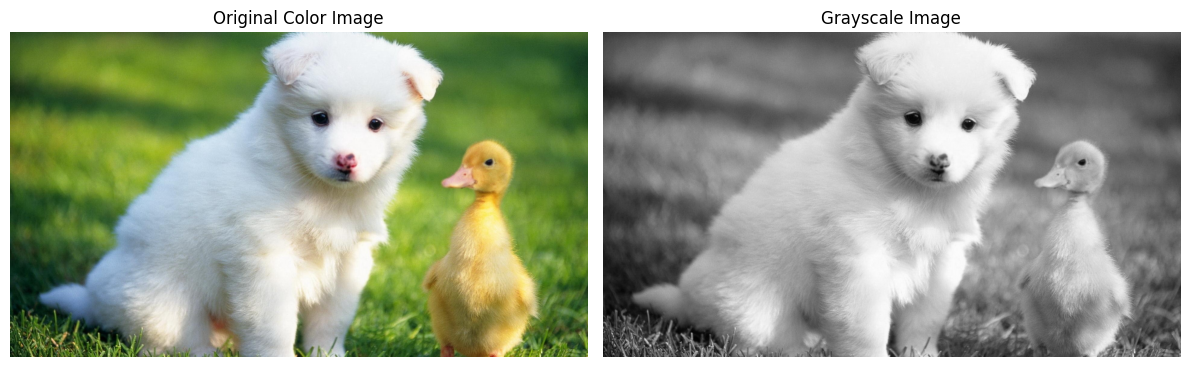

Comparison saved as: color_grayscale_comparison.png


In [2]:
import matplotlib.pyplot as plt
# Use the same image from Question 1
filename = "pic(dog).jpg"

# Open color image
color_image = Image.open(filename).convert("RGB")

# Convert to grayscale
gray_image = color_image.convert("L")

# Display both versions side by side
plt.figure(figsize=(12, 5))

# Original color image
plt.subplot(1, 2, 1)
plt.imshow(color_image)
plt.title("Original Color Image")
plt.axis("off")

# Grayscale image
plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()

# Save side-by-side comparison
output_file = "color_grayscale_comparison.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison saved as:", output_file)

**3. Develop an image format converter that takes one input image and exports it simultaneously as jpg, png, and bmp, then compares the resulting file sizes.**

       IMAGE FORMAT CONVERTER
Original File : pic(dog).jpg

JPG File Size : 364.84 KB
PNG File Size : 1978.36 KB
BMP File Size : 6075.05 KB


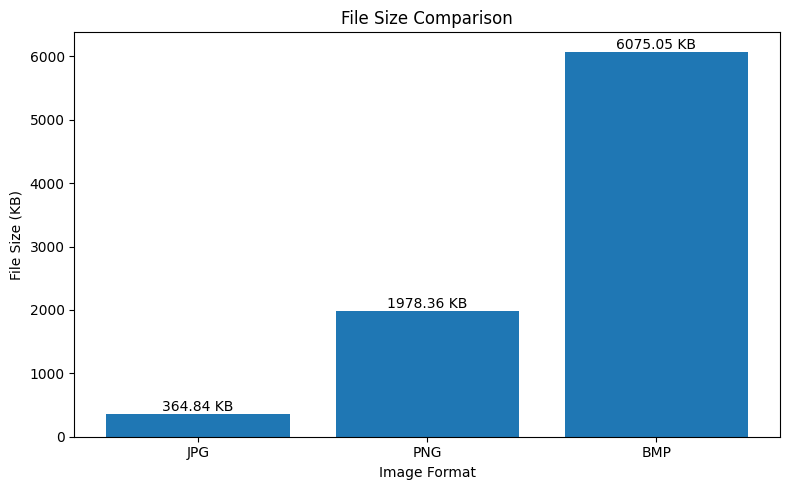

In [3]:
input_file = "pic(dog).jpg"

# Open the image
img = Image.open(input_file).convert("RGB")

# Output file names
jpg_file = "pic(dog)_converted.jpg"
png_file = "pic(dog)_converted.png"
bmp_file = "pic(dog)_converted.bmp"

# Save in different formats
img.save(jpg_file, "JPEG", quality=95)
img.save(png_file, "PNG")
img.save(bmp_file, "BMP")

# Get file sizes in KB
jpg_size = os.path.getsize(jpg_file) / 1024
png_size = os.path.getsize(png_file) / 1024
bmp_size = os.path.getsize(bmp_file) / 1024

# Display file sizes
print("========================================")
print("       IMAGE FORMAT CONVERTER")
print("========================================")

print("Original File :", input_file)
print()
print("JPG File Size :", round(jpg_size, 2), "KB")
print("PNG File Size :", round(png_size, 2), "KB")
print("BMP File Size :", round(bmp_size, 2), "KB")

print("========================================")

# Store formats and sizes
formats = ["JPG", "PNG", "BMP"]
sizes = [jpg_size, png_size, bmp_size]

# Plot comparison
plt.figure(figsize=(8, 5))
bars = plt.bar(formats, sizes)

plt.title("File Size Comparison")
plt.xlabel("Image Format")
plt.ylabel("File Size (KB)")

# Display values on bars
for bar, size in zip(bars, sizes):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{size:.2f} KB",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**4. Build a "photo negative" generator that computes and displays the complement of an uploaded image.**

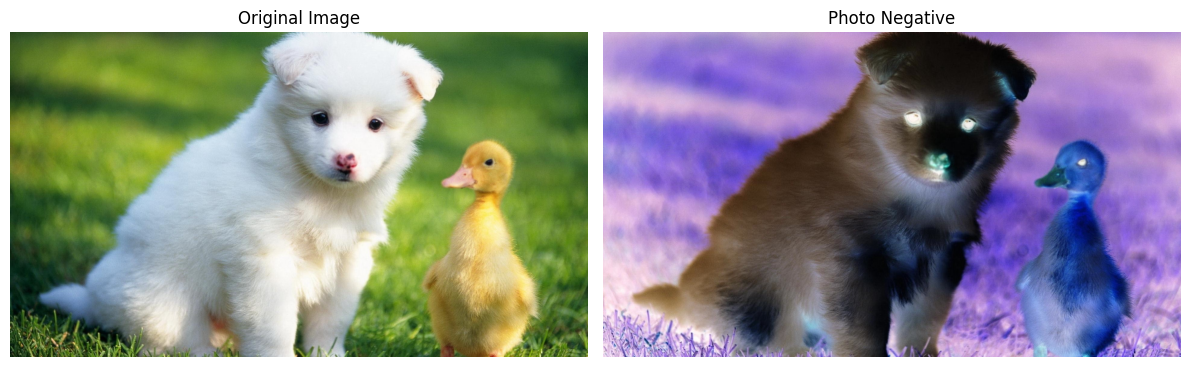

Negative image saved as: pic(dog)_negative.jpg


In [4]:
filename = "pic(dog).jpg"

# Open the image
img = Image.open(filename).convert("RGB")

# Convert image to NumPy array
img_array = np.array(img)

# Compute photo negative
negative_array = 255 - img_array

# Convert back to PIL Image
negative_image = Image.fromarray(negative_array.astype(np.uint8))

# Display original and negative images side by side
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

# Negative image
plt.subplot(1, 2, 2)
plt.imshow(negative_image)
plt.title("Photo Negative")
plt.axis("off")

plt.tight_layout()

# Save the negative image
output_file = "pic(dog)_negative.jpg"
negative_image.save(output_file)

plt.show()

print("Negative image saved as:", output_file)

**5. create a batch image resizer that reads multiple images from a folder and saves resized copies while preserving aspect ratio.**

Input folder: input_images
Output folder: resized_images

Select multiple images:


Saving pic(dog).jpg to pic(dog) (1).jpg
Saving pic(butterfly).jpg to pic(butterfly).jpg
Saving fruit_image.jpg to fruit_image.jpg

All images uploaded successfully!

       BATCH IMAGE RESIZER
fruit_image.jpg: 2048 x 1362  ->  800 x 532
pic(butterfly).jpg: 680 x 451  ->  680 x 451
pic(dog) (1).jpg: 1920 x 1080  ->  800 x 450

All images resized successfully!


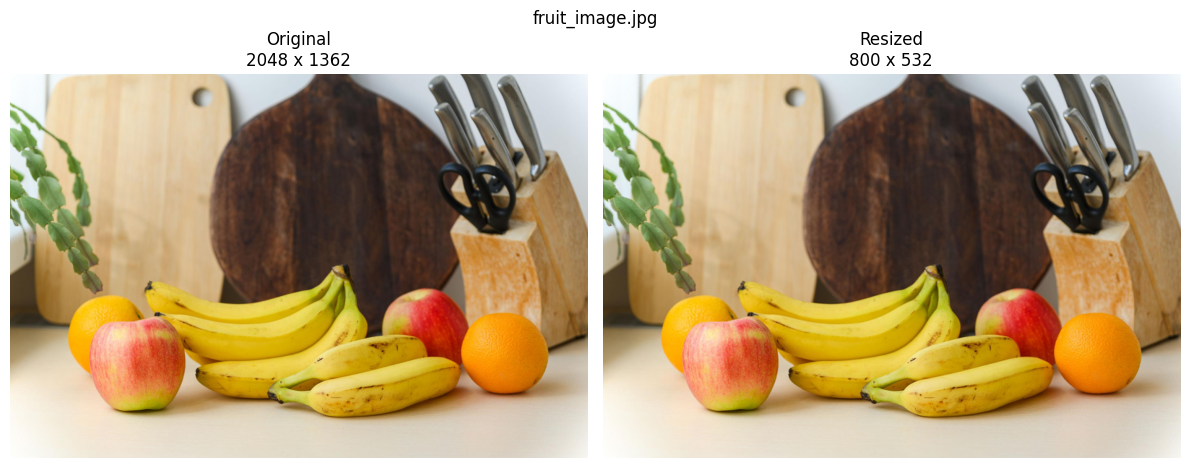

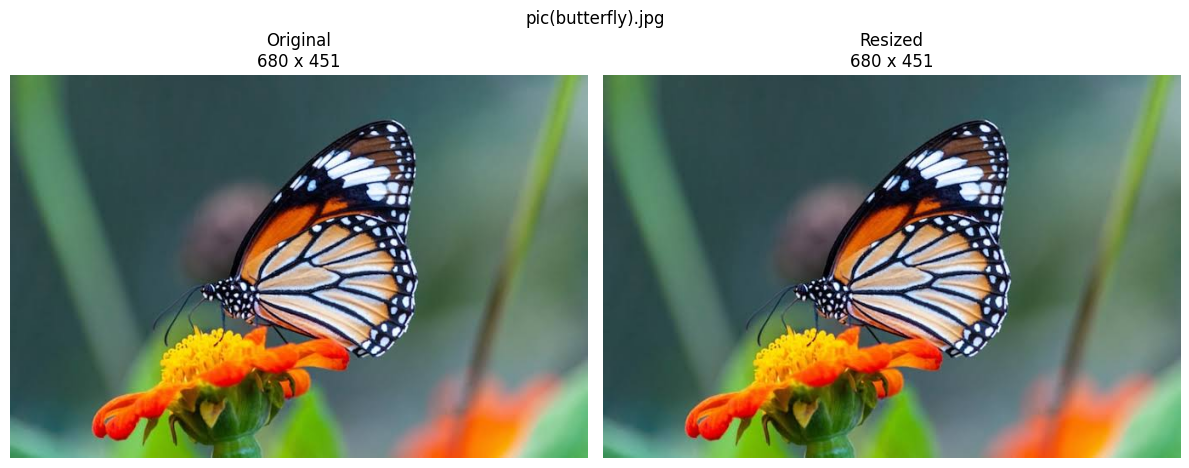

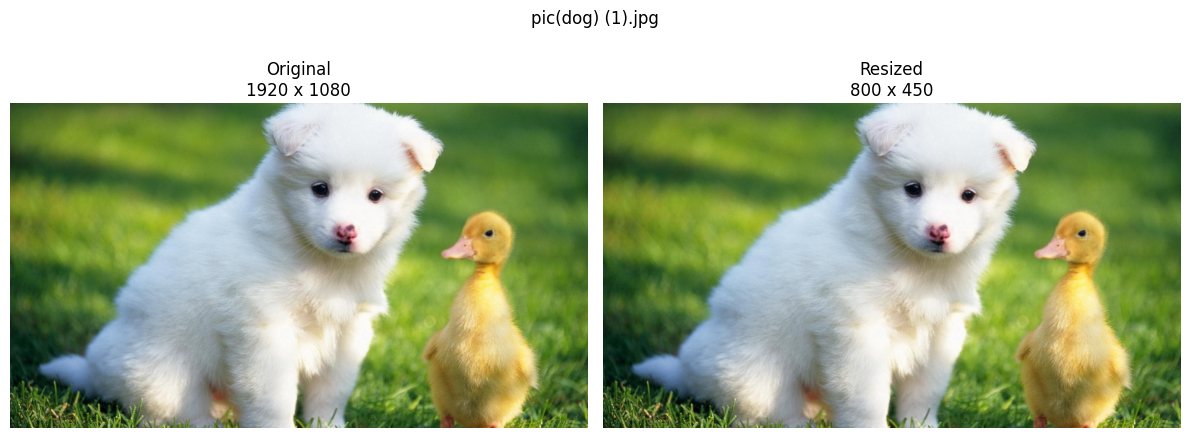


Input folder contains:
 - fruit_image.jpg
 - pic(butterfly).jpg
 - pic(dog) (1).jpg

Resized folder contains:
 - fruit_image.jpg
 - pic(butterfly).jpg
 - pic(dog) (1).jpg


In [5]:
from google.colab import files
from PIL import Image
import os
import io
import matplotlib.pyplot as plt

# STEP 1: CREATE FOLDERS

input_folder = "input_images"
output_folder = "resized_images"

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print("Input folder:", input_folder)
print("Output folder:", output_folder)


# STEP 2: UPLOAD MULTIPLE IMAGES

print("\nSelect multiple images:")

uploaded = files.upload()

# Save uploaded files directly into input_images
for filename, file_data in uploaded.items():

    output_path = os.path.join(
        input_folder,
        filename
    )

    with open(output_path, "wb") as f:
        f.write(file_data)

print("\nAll images uploaded successfully!")


# STEP 3: RESIZE SETTINGS

max_width = 800
max_height = 600

supported_formats = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp"
)


# STEP 4: RESIZE ALL IMAGES

processed_images = []

print("\n========================================")
print("       BATCH IMAGE RESIZER")
print("========================================")

for filename in os.listdir(input_folder):

    if filename.lower().endswith(supported_formats):

        input_path = os.path.join(
            input_folder,
            filename
        )

        # Open image
        img = Image.open(input_path)

        # Convert to RGB
        if img.mode not in ("RGB", "RGBA"):
            img = img.convert("RGB")

        # Original dimensions
        original_width, original_height = img.size

        # ------------------------------------
        # Calculate scale
        # ------------------------------------

        scale = min(
            max_width / original_width,
            max_height / original_height,
            1
        )

        # New dimensions
        new_width = int(original_width * scale)
        new_height = int(original_height * scale)

        # ------------------------------------
        # Resize
        # ------------------------------------

        resized_img = img.resize(
            (new_width, new_height),
            Image.Resampling.LANCZOS
        )

        # ------------------------------------
        # Save resized image
        # ------------------------------------

        output_path = os.path.join(
            output_folder,
            filename
        )

        resized_img.save(output_path)

        # Store for displaying
        processed_images.append(
            (
                filename,
                img.copy(),
                resized_img.copy()
            )
        )

        print(
            f"{filename}: "
            f"{original_width} x {original_height}"
            f"  ->  "
            f"{new_width} x {new_height}"
        )


# STEP 5: DISPLAY RESULTS

print("\n========================================")
print("All images resized successfully!")
print("========================================")

for filename, original, resized in processed_images:

    plt.figure(figsize=(12, 5))

    # Original
    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title(
        f"Original\n{original.size[0]} x {original.size[1]}"
    )
    plt.axis("off")

    # Resized
    plt.subplot(1, 2, 2)
    plt.imshow(resized)
    plt.title(
        f"Resized\n{resized.size[0]} x {resized.size[1]}"
    )
    plt.axis("off")

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()


# STEP 6: SHOW FOLDER CONTENTS

print("\nInput folder contains:")
for file in os.listdir(input_folder):
    print(" -", file)

print("\nResized folder contains:")
for file in os.listdir(output_folder):
    print(" -", file)

**6. Develop a program that crops a user-specified region of interest(ROI) from an image and saves it as separate file.**

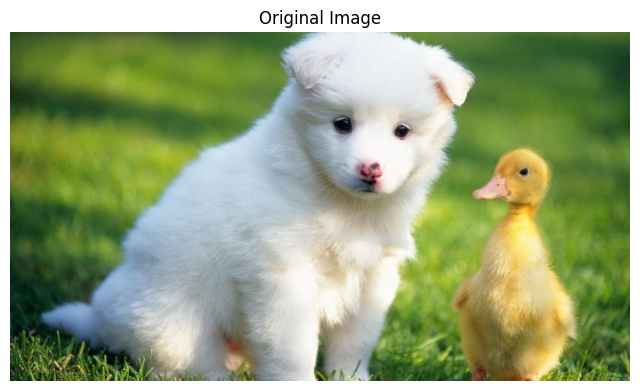

Image Size: 1920 x 1080


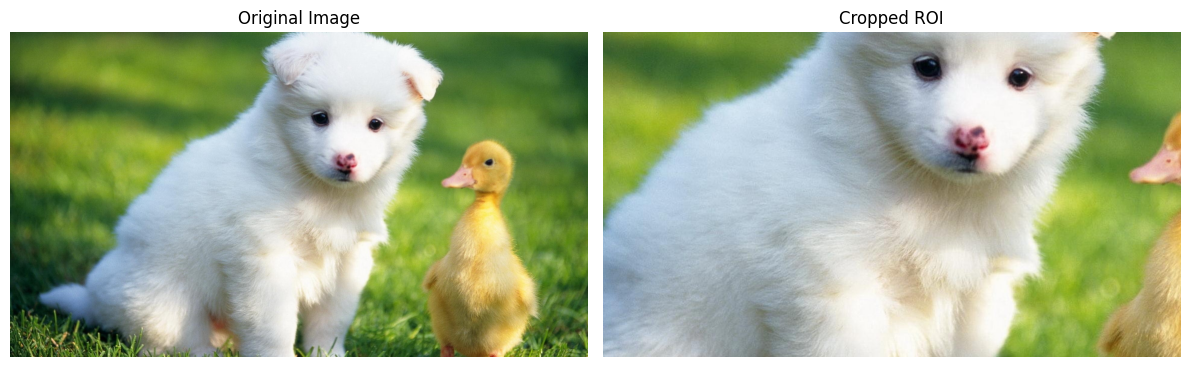

ROI saved as: pic(dog)_ROI.jpg
ROI Size: (1152, 648)


In [7]:
from PIL import Image
import matplotlib.pyplot as plt

# Load same image
filename = "pic(dog).jpg"
img = Image.open(filename).convert("RGB")

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

# Get image dimensions
width, height = img.size

print("Image Size:", width, "x", height)

# --------------------------------------------
# SPECIFY ROI
# --------------------------------------------
# Change these values according to your image

x1 = int(width * 0.20)
y1 = int(height * 0.20)

x2 = int(width * 0.80)
y2 = int(height * 0.80)

# Crop ROI
roi = img.crop((x1, y1, x2, y2))

# Save cropped image
output_file = "pic(dog)_ROI.jpg"
roi.save(output_file)

# --------------------------------------------
# DISPLAY RESULT
# --------------------------------------------

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi)
plt.title("Cropped ROI")
plt.axis("off")

plt.tight_layout()
plt.show()

print("ROI saved as:", output_file)
print("ROI Size:", roi.size)

**7. Build a tool that splits an image into its individual red,green and blue channels, then reconstructs it and verifies pixel-level accuracy.**

Original Image Shape: (1080, 1920, 3)


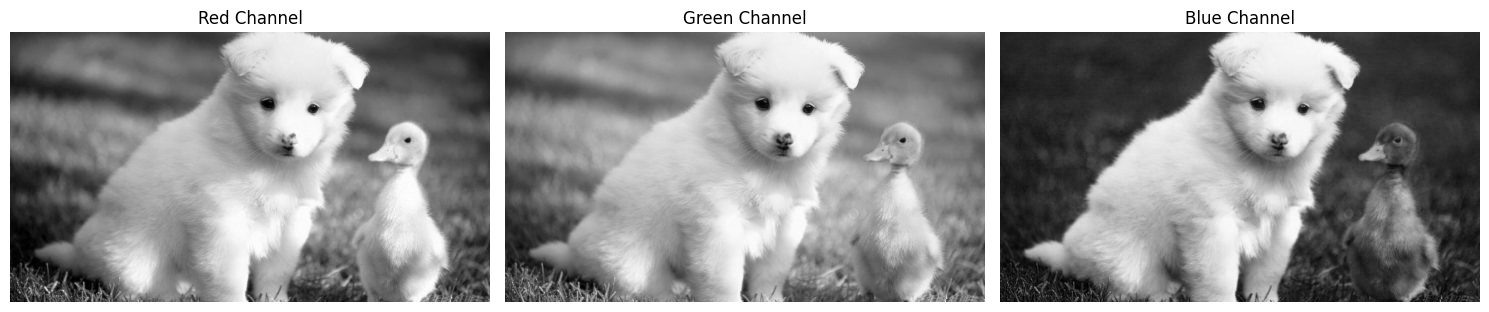

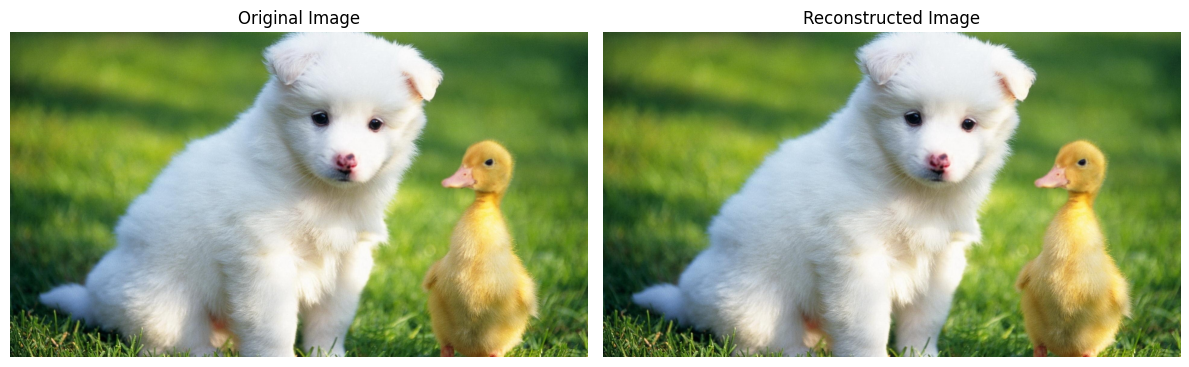

       PIXEL-LEVEL ACCURACY
Maximum Pixel Difference : 0
Different Pixel Values   : 0
Total Pixel Values       : 6220800
Result                   : EXACT MATCH
Pixel-Level Accuracy     : 100%

Reconstructed image saved as: pic(dog)_reconstructed.jpg


In [8]:
filename = "pic(dog).jpg"

img = Image.open(filename).convert("RGB")

# Convert image to NumPy array
img_array = np.array(img)

print("Original Image Shape:", img_array.shape)


# STEP 2: SPLIT RGB CHANNELS

red_channel = img_array[:, :, 0]
green_channel = img_array[:, :, 1]
blue_channel = img_array[:, :, 2]


# STEP 3: DISPLAY INDIVIDUAL CHANNELS

plt.figure(figsize=(15, 5))

# Red channel
plt.subplot(1, 3, 1)
plt.imshow(red_channel, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

# Green channel
plt.subplot(1, 3, 2)
plt.imshow(green_channel, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

# Blue channel
plt.subplot(1, 3, 3)
plt.imshow(blue_channel, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")

plt.tight_layout()
plt.show()


# STEP 4: RECONSTRUCT IMAGE

reconstructed_array = np.stack(
    (red_channel, green_channel, blue_channel),
    axis=2
)

# Convert NumPy array back to image
reconstructed_image = Image.fromarray(
    reconstructed_array.astype(np.uint8)
)


# STEP 5: DISPLAY ORIGINAL AND RECONSTRUCTED

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image)
plt.title("Reconstructed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# STEP 6: PIXEL-LEVEL ACCURACY CHECK

# Compare every pixel
pixel_difference = np.abs(
    img_array.astype(int) -
    reconstructed_array.astype(int)
)

# Maximum pixel difference
max_difference = pixel_difference.max()

# Number of different pixels
different_pixels = np.count_nonzero(
    pixel_difference
)

# Total number of values
total_values = img_array.size

# Check exact equality
exact_match = np.array_equal(
    img_array,
    reconstructed_array
)


# STEP 7: DISPLAY RESULTS

print("========================================")
print("       PIXEL-LEVEL ACCURACY")
print("========================================")

print("Maximum Pixel Difference :", max_difference)
print("Different Pixel Values   :", different_pixels)
print("Total Pixel Values       :", total_values)

if exact_match:
    print("Result                   : EXACT MATCH")
    print("Pixel-Level Accuracy     : 100%")
else:
    accuracy = (
        1 - different_pixels / total_values
    ) * 100

    print("Result                   : NOT EXACT")
    print(
        "Pixel-Level Accuracy     :",
        round(accuracy, 2),
        "%"
    )

print("========================================")


# STEP 8: SAVE RECONSTRUCTED IMAGE

output_file = "pic(dog)_reconstructed.jpg"

reconstructed_image.save(output_file)

print("\nReconstructed image saved as:", output_file)

**8. Create a watermarking utility that overlays a logo or text on an image and saves the watermarked output.**

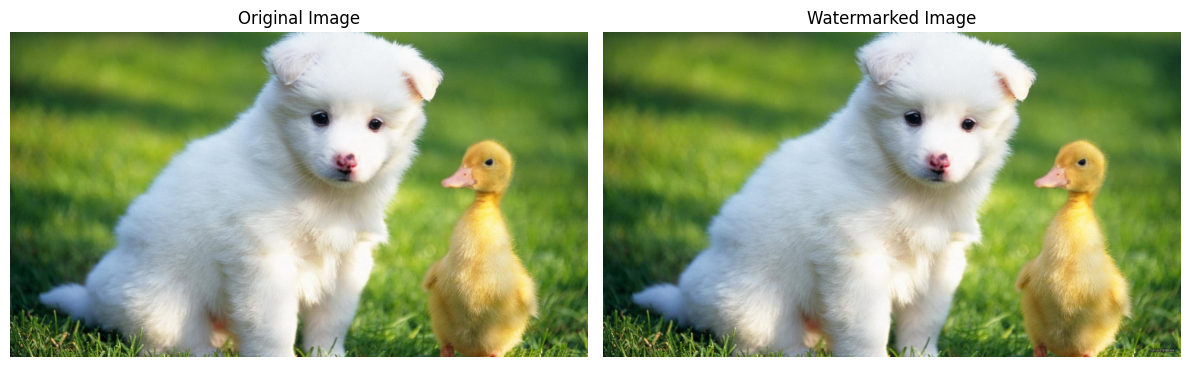

Watermarked image saved as: pic(dog)_watermarked.jpg


In [9]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

# STEP 1: LOAD IMAGE

filename = "pic(dog).jpg"

img = Image.open(filename).convert("RGBA")

# STEP 2: CREATE TRANSPARENT WATERMARK LAYER

watermark = Image.new(
    "RGBA",
    img.size,
    (255, 255, 255, 0)
)

draw = ImageDraw.Draw(watermark)

# STEP 3: WATERMARK TEXT

text = "MY WATERMARK"

# Try to use a larger font
try:
    font = ImageFont.truetype(
        "DejaVuSans-Bold.ttf",
        40
    )
except:
    font = ImageFont.load_default()

# STEP 4: FIND TEXT SIZE

bbox = draw.textbbox(
    (0, 0),
    text,
    font=font
)

text_width = bbox[2] - bbox[0]
text_height = bbox[3] - bbox[1]

# Position watermark at bottom-right
margin = 20

x = img.width - text_width - margin
y = img.height - text_height - margin

# STEP 5: DRAW WATERMARK

draw.text(
    (x, y),
    text,
    font=font,
    fill=(255, 255, 255, 180),
    stroke_width=2,
    stroke_fill=(0, 0, 0, 180)
)

# STEP 6: COMBINE IMAGE + WATERMARK

watermarked_img = Image.alpha_composite(
    img,
    watermark
)

# Convert back to RGB
watermarked_img = watermarked_img.convert("RGB")

# STEP 7: SAVE OUTPUT

output_file = "pic(dog)_watermarked.jpg"

watermarked_img.save(
    output_file,
    "JPEG",
    quality=95
)

# STEP 8: DISPLAY

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img.convert("RGB"))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(watermarked_img)
plt.title("Watermarked Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Watermarked image saved as:", output_file)